In [1]:
from pathlib import Path
import warnings

In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [4]:
from astropy.table import Column, Table
from spisea import atmospheres, reddening, synthetic

/home/wyz5rge/.venv/nbody/lib/python3.11/site-packages/pysynphot/locations.py:345: UserWarning: Extinction files not found in /home/wyz5rge/SPISEA/cdbs/extinction
  warnings.warn('Extinction files not found in %s' % (extdir, ))


----------------------------------------------------------------------
Paths
----------------------------------------------------------------------

In [5]:
ROOT = Path.cwd()

In [6]:
CACHE_DIR = ROOT / "binary_resolution_seed00_cmd_cache"
OUTPUT_DIR = ROOT / "binary_resolution_seed00_cmd_outputs"
PAPER_DIR = ROOT / "paper_figure_outputs"
PAPER_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
def first_existing(*paths):
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError(
        "None of the expected files exist:\n"
        + "\n".join(f"  {p}" for p in paths)
    )

In [8]:
METRICS_PATH = first_existing(
    CACHE_DIR / "spread_summary.csv",
    OUTPUT_DIR / "spread_metrics_binary_resolution.csv",
)

In [9]:
metrics = pd.read_csv(METRICS_PATH)

In [10]:
# Prefer the already-generated fraction table.
fraction_path = OUTPUT_DIR / "binary_resolution_fractions.csv"

In [11]:
if fraction_path.exists():
    fractions = pd.read_csv(fraction_path)

In [12]:
if not fraction_path.exists():
    # Fallback: reconstruct fractions from the cached resolution-state history.
    history_path = first_existing(
        OUTPUT_DIR / "binary_resolution_state_history.csv",
    )
    history = pd.read_csv(history_path)

    fractions = (
        history
        .groupby(
            ["snapshot_time_myr", "diagram", "projection"],
            as_index=False,
        )
        .agg(
            fraction_unresolved=("unresolved", "mean"),
            n_binaries=("pair_id", "nunique"),
        )
    )

----------------------------------------------------------------------
Labels / ordering
----------------------------------------------------------------------

In [13]:
DIAGRAMS = [
    (
        "f070w_f200w",
        "JWST F070W - F200W vs. F200W",
    ),
    (
        "f182m_f200w",
        "JWST F182M - F200W vs. F200W",
    ),
    (
        "hst_f555w_f814w",
        "HST F555W - F814W vs. F814W",
    ),
]

In [14]:
MODE_STYLE = {
    "all_resolved": {
        "label": "All resolved",
        "color": "black",
        "linestyle": "-",
        "linewidth": 2.2,
        "marker": None,
        "zorder": 3,
    },
    "all_unresolved": {
        "label": "All unresolved",
        "color": "firebrick",
        "linestyle": "-",
        "linewidth": 2.2,
        "marker": None,
        "zorder": 3,
    },
    "los_xy": {
        "label": "Rayleigh: XY",
        "color": "tab:blue",
        "linestyle": "--",
        "linewidth": 1.5,
        "marker": "o",
        "zorder": 4,
    },
    "los_xz": {
        "label": "Rayleigh: XZ",
        "color": "tab:orange",
        "linestyle": "--",
        "linewidth": 1.5,
        "marker": "s",
        "zorder": 4,
    },
    "los_yz": {
        "label": "Rayleigh: YZ",
        "color": "tab:green",
        "linestyle": "--",
        "linewidth": 1.5,
        "marker": "^",
        "zorder": 4,
    },
}

In [15]:
PROJECTION_STYLE = {
    "XY": ("tab:blue", "o"),
    "XZ": ("tab:orange", "s"),
    "YZ": ("tab:green", "^"),
}

----------------------------------------------------------------------
Main 2 x 3 paper figure
----------------------------------------------------------------------

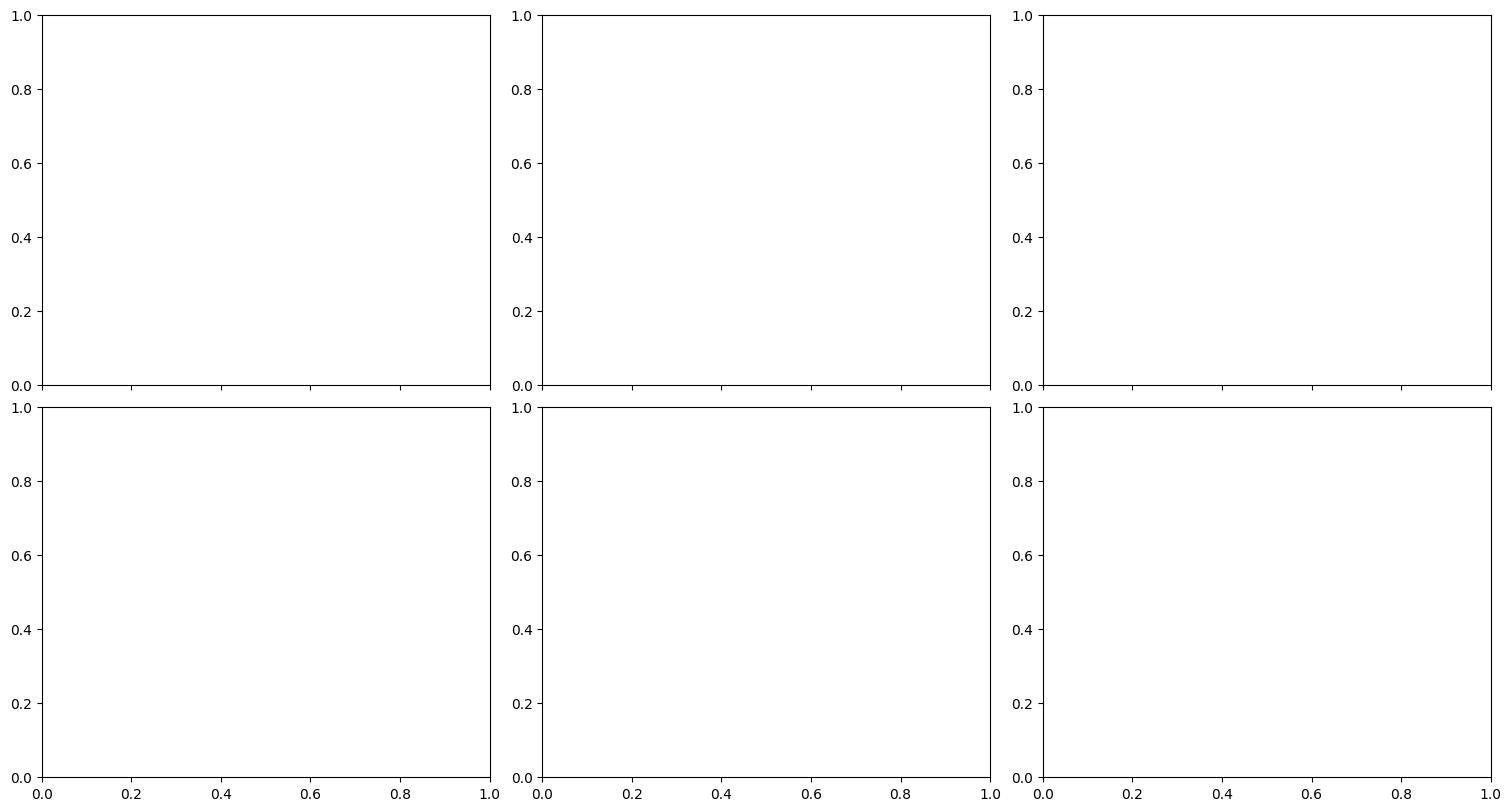

In [16]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15.0, 8.0),
    sharex="col",
    constrained_layout=True,
)

In [17]:
for col, (diagram_key, title) in enumerate(DIAGRAMS):

    # --------------------------------------------------------------
    # Top row: spread metric
    # --------------------------------------------------------------
    ax = axes[0, col]

    d = metrics[metrics["diagram"] == diagram_key].copy()

    for mode, style in MODE_STYLE.items():
        sub = (
            d[d["resolution_mode"] == mode]
            .sort_values("snapshot_time_myr")
        )

        if sub.empty:
            continue

        ax.plot(
            sub["snapshot_time_myr"],
            sub["spread_metric"],
            label=style["label"],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=style["linewidth"],
            marker=style["marker"],
            markersize=3.2,
            markevery=2,
            zorder=style["zorder"],
        )

    ax.set_title(title)
    ax.grid(alpha=0.22)

    if col == 0:
        ax.set_ylabel(
            "Mean quartile-tail spread [mag]"
        )

    # --------------------------------------------------------------
    # Bottom row: fraction unresolved
    # --------------------------------------------------------------
    ax = axes[1, col]

    f = fractions[
        fractions["diagram"] == diagram_key
    ].copy()

    for projection, (color, marker) in PROJECTION_STYLE.items():
        sub = (
            f[f["projection"].astype(str).str.upper() == projection]
            .sort_values("snapshot_time_myr")
        )

        if sub.empty:
            continue

        ax.plot(
            sub["snapshot_time_myr"],
            sub["fraction_unresolved"],
            color=color,
            marker=marker,
            markersize=3.5,
            markevery=2,
            linewidth=1.6,
            label=projection,
        )

    ax.set_ylim(0.0, 1.0)
    ax.set_xlabel("Cluster time [Myr]")
    ax.grid(alpha=0.22)

    if col == 0:
        ax.set_ylabel(
            "Fraction of current binaries unresolved"
        )

In [18]:
# Shared legend for spread modes.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.055),
)

In [19]:
fig.suptitle(
    "Effect of Binary Angular Resolution on Synthetic CMD Spread",
    y=1.07,
)

Text(0.5, 1.07, 'Effect of Binary Angular Resolution on Synthetic CMD Spread')

In [20]:
png_path = PAPER_DIR / "fig_binary_resolution_summary.png"
pdf_path = PAPER_DIR / "fig_binary_resolution_summary.pdf"

In [21]:
fig.savefig(
    png_path,
    dpi=320,
    bbox_inches="tight",
)
fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

In [22]:
print("Saved:", png_path)
print("Saved:", pdf_path)

Saved: /sfs/gpfs/tardis/home/wyz5rge/synthetic-cmd-dev/notebooks/2026/09-18-unresolved-experiment/paper_figure_outputs/fig_binary_resolution_summary.png
Saved: /sfs/gpfs/tardis/home/wyz5rge/synthetic-cmd-dev/notebooks/2026/09-18-unresolved-experiment/paper_figure_outputs/fig_binary_resolution_summary.pdf


In [23]:
plt.show()

----------------------------------------------------------------------
F182M-F200W binary-resolution CMD time evolution WITH ISOCHRONE GRID

Columns:
  1. All binaries resolved
  2. All binaries unresolved
  3. Rayleigh-limited resolution, XY sky-plane projection

Point colors:
  black      = single stars
  light blue = resolved primordial binary components
  dark blue  = unresolved primordial binaries
  dark red   = dynamically formed binaries, regardless of resolution

In the all-resolved column, every stellar source is intentionally black.

The same 1--20 Myr isochrone grid is plotted in gray in every panel.
----------------------------------------------------------------------

In [24]:
TIME_EVOLUTION_TIMES_MYR = [
    1.0,
    5.0,
    10.0,
    15.0
]

In [25]:
TIME_EVOLUTION_DIAGRAM = "f182m_f200w"

In [26]:
# Requested source colors.
COLOR_SINGLE = "black"
COLOR_PRIM_RESOLVED = "#9ecae1"       # light blue
COLOR_PRIM_UNRESOLVED = "#08519c"     # dark blue
COLOR_DYNAMIC = "#9b1c1c"             # dark red

In [27]:
POINT_SIZE = 7.0
POINT_ALPHA = 0.62

In [28]:
# Isochrone rendering.
ISOCHRONE_COLOR = "0.48"
ISOCHRONE_ALPHA = 0.28
ISOCHRONE_LINEWIDTH = 0.55

In [29]:
TRACK_JUMP_FACTOR = 12.0
TRACK_JUMP_FRACTION = 0.12
MIN_SEGMENT_POINTS = 2

----------------------------------------------------------------------
SPISEA / isochrone configuration
----------------------------------------------------------------------

In [30]:
ISO_CACHE_DIR = ROOT / "iso_cache"

In [31]:
UPDATED_MERGED_ROOT = Path(
    "/home/wyz5rge/SPISEA/evolution/merged/"
    "baraffe_pisa_ekstrom_parsec/"
)

In [32]:
if not ISO_CACHE_DIR.is_dir():
    raise FileNotFoundError(
        f"Isochrone cache directory not found: {ISO_CACHE_DIR}"
    )

In [33]:
USE_ROTATING_MERGED = False

In [34]:
AKS = 0.0
DISTANCE_PC = 410.0
METALLICITY = 0.0

In [35]:
ATM_FUNC = atmospheres.get_BTSettl_2015_atmosphere
RED_LAW = reddening.RedLawHosek18b()

In [36]:
ISO_AGES_MYR = np.arange(
    1.0,
    20.0 + 0.25,
    0.5,
)

In [37]:
ISO_LOG_AGES = np.log10(
    ISO_AGES_MYR * 1e6
)

In [38]:
FILTER_OBSMODES = {
    "F070W": "jwst,F070W",
    "F182M": "jwst,F182M",
    "F200W": "jwst,F200W",
    "F555W": "wfc3,uvis1,f555w",
    "F814W": "wfc3,uvis1,f814w",
}

In [39]:
ALL_FILTERS = list(
    FILTER_OBSMODES.values()
)

----------------------------------------------------------------------
Merged evolution model

Same model interface used by the original binary-resolution experiment.
If the SPISEA cache is complete, IsochronePhot should load the cached
products rather than regenerate them.
----------------------------------------------------------------------

In [40]:
class MergedBaraffePisaEkstromParsecDAT:

    def __init__(
        self,
        root_dir,
        rot=False,
    ):
        self.root_dir = (
            Path(root_dir)
            .expanduser()
            .resolve()
        )

        self.rot = bool(rot)

        self.model_dir = str(
            self.root_dir
        )

        self.z_list = [0.015]
        self.z_solar = 0.015
        self.mass_list = []

        self.grid_dir = (
            self.root_dir
            / (
                "z015_rot"
                if self.rot
                else "z015_norot"
            )
        )

        if not self.grid_dir.is_dir():
            raise FileNotFoundError(
                self.grid_dir
            )

        self.age_file_map = {}

        for path in sorted(
            self.grid_dir.glob(
                "iso_*.dat"
            )
        ):
            try:
                age = float(
                    path.stem.split("_")[1]
                )
            except (
                IndexError,
                ValueError,
            ):
                continue

            self.age_file_map[
                round(age, 2)
            ] = path

        if not self.age_file_map:
            raise FileNotFoundError(
                f"No iso_*.dat files in "
                f"{self.grid_dir}"
            )

        self.age_list = np.array(
            sorted(
                self.age_file_map
            ),
            dtype=float,
        )

    def isochrone(
        self,
        age=1e6,
        metallicity=0.0,
    ):

        requested = np.log10(
            float(age)
        )

        if (
            requested
            < self.age_list[0]
            or requested
            > self.age_list[-1]
        ):
            raise ValueError(
                f"logAge {requested:.4f} "
                "outside evolution grid"
            )

        selected = float(
            self.age_list[
                np.argmin(
                    np.abs(
                        self.age_list
                        - requested
                    )
                )
            ]
        )

        path = self.age_file_map[
            round(selected, 2)
        ]

        dtype = [
            ("mass", "f8"),
            ("logT", "f8"),
            ("logL", "f8"),
            ("logg", "f8"),
            ("logT_WR", "f8"),
            ("mass_current", "f8"),
            ("phase", "i4"),
            ("model_ref", "U32"),
        ]

        data = np.genfromtxt(
            path,
            comments="#",
            dtype=dtype,
            encoding="utf-8",
        )

        iso = Table(
            np.atleast_1d(data)
        )

        iso.add_column(
            Column(
                ~np.isclose(
                    np.asarray(
                        iso["logT"],
                        float,
                    ),
                    np.asarray(
                        iso["logT_WR"],
                        float,
                    ),
                    rtol=0.0,
                    atol=1e-8,
                ),
                name="isWR",
            )
        )

        iso.meta.update(
            {
                "log_age": selected,
                "log_age_requested":
                    requested,
                "metallicity_in":
                    metallicity,
                "metallicity_act": 0.0,
                "source_file":
                    str(path),
            }
        )

        return iso

In [41]:
def normalize_name(value):
    return "".join(
        ch.lower()
        for ch in str(value)
        if ch.isalnum()
    )

In [42]:
def resolve_filter_column(
    colnames,
    filter_name,
):

    target = normalize_name(
        filter_name
    )

    candidates = [
        col
        for col in colnames
        if (
            normalize_name(col)
            .startswith("m")
            and normalize_name(col)
            .endswith(target)
        )
    ]

    instrument = (
        "hst"
        if filter_name
        in {"F555W", "F814W"}
        else "jwst"
    )

    preferred = [
        col
        for col in candidates
        if instrument
        in normalize_name(col)
    ]

    if len(preferred) == 1:
        return preferred[0]

    if len(candidates) == 1:
        return candidates[0]

    raise KeyError(
        f"Cannot resolve "
        f"{filter_name}; "
        f"candidates={candidates}"
    )

----------------------------------------------------------------------
Load/cache the same 1--20 Myr isochrone grid
----------------------------------------------------------------------

In [43]:
evo_model = (
    MergedBaraffePisaEkstromParsecDAT(
        UPDATED_MERGED_ROOT,
        rot=USE_ROTATING_MERGED,
    )
)

In [44]:
ISOCHRONES = []
ISO_FILTER_COLUMNS = None

In [45]:
for age_myr, log_age in zip(
    ISO_AGES_MYR,
    ISO_LOG_AGES,
):

    print(
        f"Loading cached "
        f"{age_myr:4.1f} Myr "
        "isochrone"
    )

    with warnings.catch_warnings():
        warnings.simplefilter(
            "ignore"
        )

        iso = synthetic.IsochronePhot(
            log_age,
            AKS,
            DISTANCE_PC,
            metallicity=METALLICITY,
            evo_model=evo_model,
            atm_func=ATM_FUNC,
            red_law=RED_LAW,
            filters=ALL_FILTERS,
            iso_dir=str(
                ISO_CACHE_DIR
            ),
        )

    current_columns = {
        filter_name:
            resolve_filter_column(
                iso.points.colnames,
                filter_name,
            )
        for filter_name
        in FILTER_OBSMODES
    }

    if ISO_FILTER_COLUMNS is None:
        ISO_FILTER_COLUMNS = (
            current_columns
        )

    elif (
        current_columns
        != ISO_FILTER_COLUMNS
    ):
        raise RuntimeError(
            "Magnitude-column names "
            "changed between isochrones."
        )

    ISOCHRONES.append(
        iso
    )

Loading cached  1.0 Myr isochrone
Loading cached  1.5 Myr isochrone
Loading cached  2.0 Myr isochrone
Loading cached  2.5 Myr isochrone
Loading cached  3.0 Myr isochrone


Loading cached  3.5 Myr isochrone
Loading cached  4.0 Myr isochrone
Loading cached  4.5 Myr isochrone
Loading cached  5.0 Myr isochrone
Loading cached  5.5 Myr isochrone
Loading cached  6.0 Myr isochrone
Loading cached  6.5 Myr isochrone


Loading cached  7.0 Myr isochrone
Loading cached  7.5 Myr isochrone
Loading cached  8.0 Myr isochrone
Loading cached  8.5 Myr isochrone
Loading cached  9.0 Myr isochrone
Loading cached  9.5 Myr isochrone


Loading cached 10.0 Myr isochrone
Loading cached 10.5 Myr isochrone
Loading cached 11.0 Myr isochrone
Loading cached 11.5 Myr isochrone
Loading cached 12.0 Myr isochrone
Loading cached 12.5 Myr isochrone
Loading cached 13.0 Myr isochrone


Loading cached 13.5 Myr isochrone
Loading cached 14.0 Myr isochrone
Loading cached 14.5 Myr isochrone
Loading cached 15.0 Myr isochrone
Loading cached 15.5 Myr isochrone
Loading cached 16.0 Myr isochrone


Loading cached 16.5 Myr isochrone
Loading cached 17.0 Myr isochrone
Loading cached 17.5 Myr isochrone
Loading cached 18.0 Myr isochrone
Loading cached 18.5 Myr isochrone
Loading cached 19.0 Myr isochrone
Loading cached 19.5 Myr isochrone


Loading cached 20.0 Myr isochrone


----------------------------------------------------------------------
Convert isochrones into F182M-F200W vs. F200W
----------------------------------------------------------------------

In [46]:
def isochrone_f182m_f200w(
    iso,
):

    mass = np.asarray(
        iso.points["mass"],
        float,
    )

    m182 = np.asarray(
        iso.points[
            ISO_FILTER_COLUMNS[
                "F182M"
            ]
        ],
        float,
    )

    m200 = np.asarray(
        iso.points[
            ISO_FILTER_COLUMNS[
                "F200W"
            ]
        ],
        float,
    )

    x = m182 - m200
    y = m200

    return x, y, mass

----------------------------------------------------------------------
Safe isochrone rendering

Sort in mass and break the merged tracks at unusually large jumps so
discontinuous model branches are not connected by artificial diagonals.
----------------------------------------------------------------------

In [47]:
def split_continuous_isochrone(
    x,
    y,
    mass,
):

    x = np.asarray(
        x,
        float,
    )

    y = np.asarray(
        y,
        float,
    )

    mass = np.asarray(
        mass,
        float,
    )

    good = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(mass)
    )

    x = x[good]
    y = y[good]
    mass = mass[good]

    if (
        len(x)
        < MIN_SEGMENT_POINTS
    ):
        return []

    order = np.argsort(
        mass,
        kind="stable",
    )

    x = x[order]
    y = y[order]

    dx = np.abs(
        np.diff(x)
    )

    dy = np.abs(
        np.diff(y)
    )

    x_span = (
        np.nanmax(x)
        - np.nanmin(x)
    )

    y_span = (
        np.nanmax(y)
        - np.nanmin(y)
    )

    positive_dx = dx[
        dx > 0
    ]

    positive_dy = dy[
        dy > 0
    ]

    median_dx = (
        np.nanmedian(
            positive_dx
        )
        if len(positive_dx)
        else 0.0
    )

    median_dy = (
        np.nanmedian(
            positive_dy
        )
        if len(positive_dy)
        else 0.0
    )

    x_threshold = max(
        TRACK_JUMP_FACTOR
        * median_dx,
        TRACK_JUMP_FRACTION
        * x_span,
    )

    y_threshold = max(
        TRACK_JUMP_FACTOR
        * median_dy,
        TRACK_JUMP_FRACTION
        * y_span,
    )

    if x_threshold <= 0:
        x_threshold = np.inf

    if y_threshold <= 0:
        y_threshold = np.inf

    breaks = (
        (dx > x_threshold)
        | (dy > y_threshold)
    )

    split_indices = (
        np.where(breaks)[0]
        + 1
    )

    x_parts = np.split(
        x,
        split_indices,
    )

    y_parts = np.split(
        y,
        split_indices,
    )

    return [
        (xp, yp)
        for xp, yp
        in zip(
            x_parts,
            y_parts,
        )
        if (
            len(xp)
            >= MIN_SEGMENT_POINTS
        )
    ]

In [48]:
def plot_isochrone_grid(ax):

    for iso in ISOCHRONES:

        x_iso, y_iso, mass = (
            isochrone_f182m_f200w(
                iso
            )
        )

        segments = (
            split_continuous_isochrone(
                x_iso,
                y_iso,
                mass,
            )
        )

        for xs, ys in segments:

            ax.plot(
                xs,
                ys,
                color=ISOCHRONE_COLOR,
                linewidth=(
                    ISOCHRONE_LINEWIDTH
                ),
                alpha=ISOCHRONE_ALPHA,
                zorder=1,
            )

----------------------------------------------------------------------
Load the F200W Rayleigh threshold from the original experiment
----------------------------------------------------------------------

In [49]:
resolution_table_path = (
    first_existing(
        OUTPUT_DIR
        / "instrument_resolution_thresholds.csv",
    )
)

In [50]:
resolution_table = pd.read_csv(
    resolution_table_path
)

In [51]:
resolution_row = (
    resolution_table[
        resolution_table[
            "diagram"
        ]
        == TIME_EVOLUTION_DIAGRAM
    ]
)

In [52]:
if len(resolution_row) != 1:

    raise RuntimeError(
        "Expected exactly one "
        "F182M-F200W resolution "
        f"row; found "
        f"{len(resolution_row)}."
    )

In [53]:
resolution_row = (
    resolution_row.iloc[0]
)

In [54]:
RAYLEIGH_THRESHOLD_PC = float(
    resolution_row[
        "physical_resolution_pc"
    ]
)

In [55]:
RAYLEIGH_THRESHOLD_AU = float(
    resolution_row[
        "physical_resolution_au"
    ]
)

In [56]:
RAYLEIGH_THRESHOLD_ARCSEC = float(
    resolution_row[
        "theta_arcsec"
    ]
)

In [57]:
print(
    "F182M-F200W XY "
    "Rayleigh criterion:"
    f" {RAYLEIGH_THRESHOLD_ARCSEC:.4f}"
    " arcsec"
    f" = {RAYLEIGH_THRESHOLD_AU:.2f}"
    " AU"
)

F182M-F200W XY Rayleigh criterion: 0.0774 arcsec = 31.75 AU


----------------------------------------------------------------------
Cached base-catalog helpers
----------------------------------------------------------------------

In [58]:
def cached_base_catalog_path(
    time_myr,
):

    return (
        CACHE_DIR
        / "base_catalogs"
        / (
            f"photometry_"
            f"t{float(time_myr):04.1f}"
            "myr.csv"
        )
    )

In [59]:
def load_cached_base_catalog(
    time_myr,
):

    path = (
        cached_base_catalog_path(
            time_myr
        )
    )

    if not path.exists():

        raise FileNotFoundError(
            "Cached photometric "
            "catalog not found:\n"
            f"{path}"
        )

    return pd.read_csv(
        path,
        dtype={
            "pair_id": str
        },
    )

In [60]:
def bool_array(series):

    if (
        pd.api.types
        .is_bool_dtype(series)
    ):
        return (
            series.to_numpy(bool)
        )

    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "yes",
            ]
        )
        .to_numpy(bool)
    )

----------------------------------------------------------------------
Stellar CMD coordinates
----------------------------------------------------------------------

In [61]:
def cmd_xy_from_magnitudes(
    m182,
    m200,
):

    m182 = np.asarray(
        m182,
        float,
    )

    m200 = np.asarray(
        m200,
        float,
    )

    return (
        m182 - m200,
        m200,
    )

In [62]:
def finite_xy(x, y):

    x = np.asarray(
        x,
        float,
    )

    y = np.asarray(
        y,
        float,
    )

    good = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    return (
        x[good],
        y[good],
    )

In [63]:
def add_group(
    groups,
    label,
    x,
    y,
):

    x, y = finite_xy(
        x,
        y,
    )

    if len(x) == 0:
        return

    if label not in groups:
        groups[label] = {
            "x": [],
            "y": [],
        }

    groups[label]["x"].append(
        x
    )

    groups[label]["y"].append(
        y
    )

In [64]:
def finalize_groups(groups):

    output = {}

    for key, values in (
        groups.items()
    ):

        output[key] = {
            "x": np.concatenate(
                values["x"]
            ),
            "y": np.concatenate(
                values["y"]
            ),
        }

    return output

----------------------------------------------------------------------
Construct one of the three binary-resolution representations
----------------------------------------------------------------------

In [65]:
def build_cmd_groups(
    base,
    mode,
):

    groups = {}

    is_multiple = bool_array(
        base["is_multiple"]
    )

    primordial = bool_array(
        base[
            "is_primordial_pair"
        ]
    )

    dynamic = bool_array(
        base[
            "is_dynamically_formed_pair"
        ]
    )

    # --------------------------------------------------------------
    # Single stars
    # --------------------------------------------------------------

    singles = ~is_multiple

    x, y = (
        cmd_xy_from_magnitudes(
            base.loc[
                singles,
                "primary_mag_F182M",
            ],
            base.loc[
                singles,
                "primary_mag_F200W",
            ],
        )
    )

    add_group(
        groups,
        "single",
        x,
        y,
    )

    # --------------------------------------------------------------
    # Current binaries
    # --------------------------------------------------------------

    binary_indices = np.where(
        is_multiple
    )[0]

    for i in binary_indices:

        row = base.iloc[i]

        is_prim = bool(
            primordial[i]
        )

        is_dyn = bool(
            dynamic[i]
        )

        if is_prim == is_dyn:

            raise RuntimeError(
                "Binary origin "
                "classification is "
                "ambiguous for pair "
                f"{row.get('pair_id', i)}"
            )

        # ----------------------------------------------------------
        # Resolution state
        # ----------------------------------------------------------

        if mode == "all_resolved":

            unresolved = False

        elif mode == "all_unresolved":

            unresolved = True

        elif mode == "los_xy":

            separation_pc = float(
                row["sep_xy_pc"]
            )

            if not np.isfinite(
                separation_pc
            ):

                raise RuntimeError(
                    "Non-finite XY "
                    "separation for pair "
                    f"{row.get('pair_id', i)}"
                )

            unresolved = (
                separation_pc
                <= RAYLEIGH_THRESHOLD_PC
            )

        else:

            raise ValueError(
                "Unknown mode: "
                f"{mode}"
            )

        # ----------------------------------------------------------
        # All-resolved reference:
        # every stellar source black.
        # ----------------------------------------------------------

        if mode == "all_resolved":

            xp, yp = (
                cmd_xy_from_magnitudes(
                    [
                        row[
                            "primary_mag_F182M"
                        ]
                    ],
                    [
                        row[
                            "primary_mag_F200W"
                        ]
                    ],
                )
            )

            xs, ys = (
                cmd_xy_from_magnitudes(
                    [
                        row[
                            "secondary_mag_F182M"
                        ]
                    ],
                    [
                        row[
                            "secondary_mag_F200W"
                        ]
                    ],
                )
            )

            add_group(
                groups,
                "all_resolved_black",
                xp,
                yp,
            )

            add_group(
                groups,
                "all_resolved_black",
                xs,
                ys,
            )

            continue

        # ----------------------------------------------------------
        # Unresolved binary:
        # one combined source
        # ----------------------------------------------------------

        if unresolved:

            x, y = (
                cmd_xy_from_magnitudes(
                    [
                        row[
                            "combined_mag_F182M"
                        ]
                    ],
                    [
                        row[
                            "combined_mag_F200W"
                        ]
                    ],
                )
            )

            if is_dyn:
                label = "dynamic"
            else:
                label = (
                    "primordial_unresolved"
                )

            add_group(
                groups,
                label,
                x,
                y,
            )

        # ----------------------------------------------------------
        # Resolved binary:
        # two component sources
        # ----------------------------------------------------------

        else:

            xp, yp = (
                cmd_xy_from_magnitudes(
                    [
                        row[
                            "primary_mag_F182M"
                        ]
                    ],
                    [
                        row[
                            "primary_mag_F200W"
                        ]
                    ],
                )
            )

            xs, ys = (
                cmd_xy_from_magnitudes(
                    [
                        row[
                            "secondary_mag_F182M"
                        ]
                    ],
                    [
                        row[
                            "secondary_mag_F200W"
                        ]
                    ],
                )
            )

            if is_dyn:
                label = "dynamic"
            else:
                label = (
                    "primordial_resolved"
                )

            add_group(
                groups,
                label,
                xp,
                yp,
            )

            add_group(
                groups,
                label,
                xs,
                ys,
            )

    return finalize_groups(
        groups
    )

----------------------------------------------------------------------
Construct all six times x three observing modes
----------------------------------------------------------------------

In [66]:
TIME_EVOLUTION_MODES = [
    "all_resolved",
    "all_unresolved",
    "los_xy",
]

In [67]:
time_evolution_groups = {}

In [68]:
for time_myr in (
    TIME_EVOLUTION_TIMES_MYR
):

    base = (
        load_cached_base_catalog(
            time_myr
        )
    )

    for mode in (
        TIME_EVOLUTION_MODES
    ):

        time_evolution_groups[
            (time_myr, mode)
        ] = build_cmd_groups(
            base,
            mode,
        )

----------------------------------------------------------------------
Shared plotting limits

Include BOTH the stellar catalogs and the full isochrone grid.
----------------------------------------------------------------------

In [69]:
all_plot_x = []
all_plot_y = []

In [70]:
for groups in (
    time_evolution_groups.values()
):

    for values in groups.values():

        all_plot_x.append(
            values["x"]
        )

        all_plot_y.append(
            values["y"]
        )

In [71]:
# Also include every isochrone in the limits.
for iso in ISOCHRONES:

    x_iso, y_iso, _ = (
        isochrone_f182m_f200w(
            iso
        )
    )

    good_iso = (
        np.isfinite(x_iso)
        & np.isfinite(y_iso)
    )

    all_plot_x.append(
        x_iso[good_iso]
    )

    all_plot_y.append(
        y_iso[good_iso]
    )

In [72]:
all_plot_x = np.concatenate(
    all_plot_x
)

In [73]:
all_plot_y = np.concatenate(
    all_plot_y
)

In [74]:
good = (
    np.isfinite(all_plot_x)
    & np.isfinite(all_plot_y)
)

In [75]:
all_plot_x = all_plot_x[
    good
]

In [76]:
all_plot_y = all_plot_y[
    good
]

In [77]:
x_min = float(
    np.min(all_plot_x)
)

In [78]:
x_max = float(
    np.max(all_plot_x)
)

In [79]:
y_min = float(
    np.min(all_plot_y)
)

In [80]:
y_max = float(
    np.max(all_plot_y)
)

In [81]:
x_span = x_max - x_min
y_span = y_max - y_min

In [82]:
x_pad = (
    0.03 * x_span
    if x_span > 0
    else 0.1
)

In [83]:
y_pad = (
    0.03 * y_span
    if y_span > 0
    else 0.1
)

----------------------------------------------------------------------
Point plotting styles
----------------------------------------------------------------------

In [84]:
POINT_STYLES = {

    "single": {
        "color": COLOR_SINGLE,
        "zorder": 4,
    },

    "all_resolved_black": {
        "color": COLOR_SINGLE,
        "zorder": 4,
    },

    "primordial_resolved": {
        "color": (
            COLOR_PRIM_RESOLVED
        ),
        "zorder": 5,
    },

    "primordial_unresolved": {
        "color": (
            COLOR_PRIM_UNRESOLVED
        ),
        "zorder": 6,
    },

    "dynamic": {
        "color": COLOR_DYNAMIC,
        "zorder": 7,
    },
}

In [85]:
def plot_cmd_groups(
    ax,
    groups,
):

    # Isochrones go down first.
    plot_isochrone_grid(
        ax
    )

    # Then stellar sources.
    plot_order = [
        "single",
        "all_resolved_black",
        "primordial_resolved",
        "primordial_unresolved",
        "dynamic",
    ]

    for key in plot_order:

        if key not in groups:
            continue

        style = (
            POINT_STYLES[key]
        )

        values = groups[key]

        ax.scatter(
            values["x"],
            values["y"],
            s=POINT_SIZE,
            color=style["color"],
            alpha=POINT_ALPHA,
            edgecolors="none",
            rasterized=True,
            zorder=style["zorder"],
        )

    ax.grid(
        alpha=0.14,
        linewidth=0.6,
    )

----------------------------------------------------------------------
6 x 3 figure
----------------------------------------------------------------------

In [86]:
nrows = len(
    TIME_EVOLUTION_TIMES_MYR
)

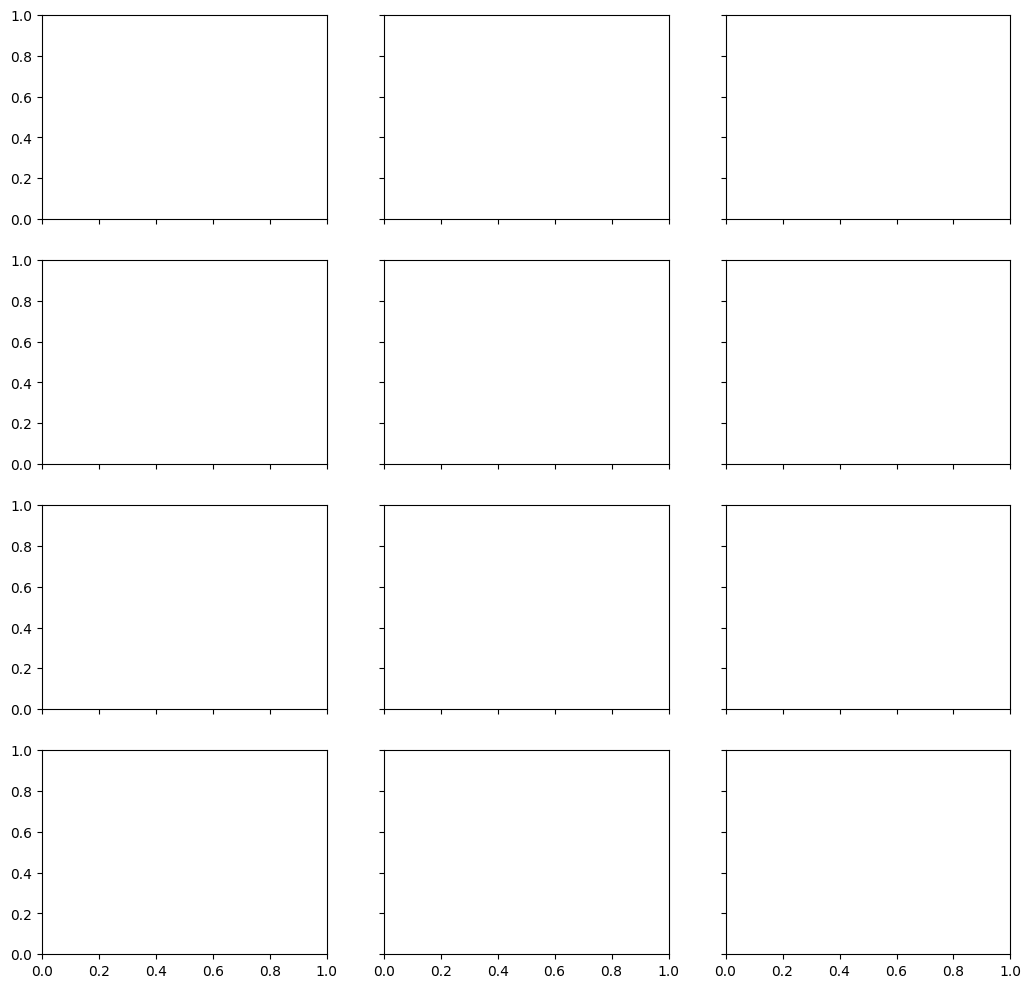

In [87]:
fig, axes = plt.subplots(
    nrows,
    3,
    figsize=(
        12.5,
        3.05 * nrows,
    ),
    sharex=True,
    sharey=True,
    constrained_layout=False,
    squeeze=False,
)

In [88]:
fig.subplots_adjust(
    left=0.085,
    right=0.985,
    bottom=0.055,
    top=0.895,
    hspace=0.16,
    wspace=0.08,
)

In [89]:
COLUMN_MODES = [
    "all_resolved",
    "all_unresolved",
    "los_xy",
]

In [90]:
COLUMN_TITLES = [
    "All Binaries Resolved",
    "All Binaries Unresolved",
    "Rayleigh Criterion: XY Projection",
]

In [91]:
for row, time_myr in enumerate(
    TIME_EVOLUTION_TIMES_MYR
):

    for col, mode in enumerate(
        COLUMN_MODES
    ):

        ax = axes[row, col]

        groups = (
            time_evolution_groups[
                (time_myr, mode)
            ]
        )

        plot_cmd_groups(
            ax,
            groups,
        )

        # Same exact viewport in every panel.
        ax.set_xlim(
            x_min - x_pad,
            x_max + x_pad,
        )

        # Magnitude axis:
        # larger/fainter magnitudes at bottom.
        ax.set_ylim(
            y_max + y_pad,
            y_min - y_pad,
        )

        if row == 0:

            ax.set_title(
                COLUMN_TITLES[col],
                fontsize=11,
                pad=7,
            )

        if col == 0:

            ax.text(
                0.03,
                0.94,
                (
                    rf"$t_{{\rm cl}}"
                    rf"={time_myr:g}$ Myr"
                ),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.76,
                    pad=2.0,
                ),
                zorder=20,
            )

        if row == nrows - 1:

            ax.set_xlabel(
                "F182M - F200W"
            )

        if col == 0:

            ax.set_ylabel(
                "F200W"
            )

----------------------------------------------------------------------
Legend
----------------------------------------------------------------------

In [92]:
legend_handles = [

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=(
            COLOR_SINGLE
        ),
        markeredgecolor="none",
        markersize=6,
        label="Single stars",
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=(
            COLOR_PRIM_RESOLVED
        ),
        markeredgecolor="none",
        markersize=6,
        label=(
            "Resolved primordial components"
        ),
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=(
            COLOR_PRIM_UNRESOLVED
        ),
        markeredgecolor="none",
        markersize=6,
        label=(
            "Unresolved primordial binaries"
        ),
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=(
            COLOR_DYNAMIC
        ),
        markeredgecolor="none",
        markersize=6,
        label=(
            "Dynamically formed binaries"
        ),
    ),

    Line2D(
        [0],
        [0],
        color=ISOCHRONE_COLOR,
        linewidth=1.5,
        alpha=0.8,
        label="1--20 Myr isochrones",
    ),
]

In [93]:
fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.955,
    ),
    fontsize=8.5,
    columnspacing=1.3,
    handletextpad=0.5,
)

In [94]:
fig.suptitle(
    "Evolution of Binary Resolution in "
    "F182M-F200W vs. F200W",
    fontsize=15,
    y=0.988,
)

Text(0.5, 0.988, 'Evolution of Binary Resolution in F182M-F200W vs. F200W')

In [95]:
fig.text(
    0.5,
    0.925,
    (
        rf"$M_{{\rm cl}}"
        rf"=3000\,M_\odot$, "
        rf"$\Sigma_{{\rm cloud}}"
        rf"=0.1\,"
        rf"\mathrm{{g\,cm^{{-2}}}}$, "
        rf"$\epsilon_{{\rm ff}}"
        rf"=0.03$, seed 00; "
        rf"Rayleigh threshold "
        rf"= "
        rf"{RAYLEIGH_THRESHOLD_ARCSEC:.3f}"
        rf" arcsec "
        rf"("
        rf"{RAYLEIGH_THRESHOLD_AU:.1f}"
        rf" AU at 410 pc)"
    ),
    ha="center",
    va="center",
    fontsize=9,
)

Text(0.5, 0.925, '$M_{\\rm cl}=3000\\,M_\\odot$, $\\Sigma_{\\rm cloud}=0.1\\,\\mathrm{g\\,cm^{-2}}$, $\\epsilon_{\\rm ff}=0.03$, seed 00; Rayleigh threshold = 0.077 arcsec (31.7 AU at 410 pc)')

----------------------------------------------------------------------
Save
----------------------------------------------------------------------

In [96]:
time_png = (
    PAPER_DIR
    / (
        "fig_binary_resolution_"
        "cmd_time_evolution_"
        "f182m_f200w.png"
    )
)

In [97]:
time_pdf = (
    PAPER_DIR
    / (
        "fig_binary_resolution_"
        "cmd_time_evolution_"
        "f182m_f200w.pdf"
    )
)

In [98]:
fig.savefig(
    time_png,
    dpi=320,
    bbox_inches="tight",
)

In [99]:
fig.savefig(
    time_pdf,
    bbox_inches="tight",
)

In [100]:
print(
    "Saved:",
    time_png,
)

Saved: /sfs/gpfs/tardis/home/wyz5rge/synthetic-cmd-dev/notebooks/2026/09-18-unresolved-experiment/paper_figure_outputs/fig_binary_resolution_cmd_time_evolution_f182m_f200w.png


In [101]:
print(
    "Saved:",
    time_pdf,
)

Saved: /sfs/gpfs/tardis/home/wyz5rge/synthetic-cmd-dev/notebooks/2026/09-18-unresolved-experiment/paper_figure_outputs/fig_binary_resolution_cmd_time_evolution_f182m_f200w.pdf


In [102]:
plt.show()

----------------------------------------------------------------------
Quantify the results for manuscript text
----------------------------------------------------------------------

In [103]:
# Put the five spread modes into columns at each diagram/time.
spread_wide = (
    metrics
    .pivot_table(
        index=["diagram", "snapshot_time_myr"],
        columns="resolution_mode",
        values="spread_metric",
        aggfunc="first",
    )
    .reset_index()
)

In [104]:
records = []

In [105]:
for diagram_key, title in DIAGRAMS:

    d = spread_wide[
        spread_wide["diagram"] == diagram_key
    ].copy()

    required = {
        "all_resolved",
        "all_unresolved",
        "los_xy",
        "los_xz",
        "los_yz",
    }

    if not required.issubset(d.columns):
        print(
            f"Skipping manuscript statistics for {diagram_key}; "
            "not all five modes are present."
        )
        continue

    extreme_offset = (
        d["all_unresolved"] - d["all_resolved"]
    )

    los_array = d[
        ["los_xy", "los_xz", "los_yz"]
    ].to_numpy(float)

    los_projection_range = (
        np.nanmax(los_array, axis=1)
        - np.nanmin(los_array, axis=1)
    )

    for projection, mode in [
        ("XY", "los_xy"),
        ("XZ", "los_xz"),
        ("YZ", "los_yz"),
    ]:

        frac = fractions[
            (fractions["diagram"] == diagram_key)
            & (
                fractions["projection"]
                .astype(str)
                .str.upper()
                == projection
            )
        ][
            [
                "snapshot_time_myr",
                "fraction_unresolved",
            ]
        ].copy()

        tmp = d[
            [
                "snapshot_time_myr",
                "all_resolved",
                "all_unresolved",
                mode,
            ]
        ].merge(
            frac,
            on="snapshot_time_myr",
            how="inner",
        )

        denom = (
            tmp["all_unresolved"]
            - tmp["all_resolved"]
        )

        good = (
            np.isfinite(denom)
            & (np.abs(denom) > 1e-12)
        )

        relative_position = np.full(
            len(tmp),
            np.nan,
            dtype=float,
        )

        relative_position[good] = (
            (
                tmp.loc[good, mode]
                - tmp.loc[good, "all_resolved"]
            )
            / denom[good]
        )

        los_offset = (
            tmp[mode]
            - tmp["all_resolved"]
        )

        records.append(
            {
                "diagram": diagram_key,
                "diagram_title": title,
                "projection": projection,

                "mean_fraction_unresolved":
                    tmp["fraction_unresolved"].mean(),

                "min_fraction_unresolved":
                    tmp["fraction_unresolved"].min(),

                "max_fraction_unresolved":
                    tmp["fraction_unresolved"].max(),

                "mean_all_unresolved_minus_resolved_spread":
                    extreme_offset.mean(),

                "std_all_unresolved_minus_resolved_spread":
                    extreme_offset.std(ddof=1),

                "mean_los_minus_resolved_spread":
                    los_offset.mean(),

                "std_los_minus_resolved_spread":
                    los_offset.std(ddof=1),

                # 0 = resolved limit
                # 1 = unresolved limit
                "mean_los_position_between_extremes":
                    np.nanmean(relative_position),

                "std_los_position_between_extremes":
                    np.nanstd(relative_position, ddof=1),

                "mean_spread_range_across_viewing_axes":
                    np.nanmean(los_projection_range),

                "max_spread_range_across_viewing_axes":
                    np.nanmax(los_projection_range),
            }
        )

In [106]:
summary = pd.DataFrame(records)

In [107]:
summary_path = (
    PAPER_DIR
    / "binary_resolution_paper_summary_statistics.csv"
)

In [108]:
summary.to_csv(
    summary_path,
    index=False,
)

In [109]:
print("\n" + "=" * 90)
print("BINARY-RESOLUTION MANUSCRIPT SUMMARY")
print("=" * 90)
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)


BINARY-RESOLUTION MANUSCRIPT SUMMARY
        diagram                diagram_title projection  mean_fraction_unresolved  min_fraction_unresolved  max_fraction_unresolved  mean_all_unresolved_minus_resolved_spread  std_all_unresolved_minus_resolved_spread  mean_los_minus_resolved_spread  std_los_minus_resolved_spread  mean_los_position_between_extremes  std_los_position_between_extremes  mean_spread_range_across_viewing_axes  max_spread_range_across_viewing_axes
    f070w_f200w JWST F070W - F200W vs. F200W         XY                    0.7514                   0.6767                   0.7653                                     0.3387                                    0.0997                          0.2774                         0.0907                              0.8098                             0.0627                                 0.0115                                0.0358
    f070w_f200w JWST F070W - F200W vs. F200W         XZ                    0.7733                   0.6810

In [110]:
print("\nSaved:", summary_path)


Saved: /sfs/gpfs/tardis/home/wyz5rge/synthetic-cmd-dev/notebooks/2026/09-18-unresolved-experiment/paper_figure_outputs/binary_resolution_paper_summary_statistics.csv
